In [1]:
import scipy.io as sio
import pickle
import matplotlib.pyplot as plt
import numpy as np
import sys
sys.path.append('../../')
from helper_function import *
cobra.Configuration.solver = 'glpk'

In [2]:
cmap = plt.get_cmap('coolwarm')
num_colors = 20
colors = [cmap(i / num_colors) for i in range(num_colors)]

set_color = colors[19] #17 18
scatter_color = colors[18] #3 2

model = cobra.io.load_matlab_model("../../universal_model.mat")

with open('../../FBAsolution/M9_sufficient_423_1_proteome_weakbg.pkl', 'rb') as pickle_file:
    data = pickle.load(pickle_file)
    all_total_nutrient_count = data['all_total_nutrient_count']
    all_total_intake = data['all_total_intake']
    all_growth_rate = data['all_growth_rate']
    all_random_medium = data['all_random_medium']
    all_met_flux = data['all_met_flux']
    del data

{'r': 0.49436074686687853, 'p': 7.586627250271927e-14, 'ci_low': 0.3824079392629988, 'ci_high': 0.5920089174020975, 'n': 202}


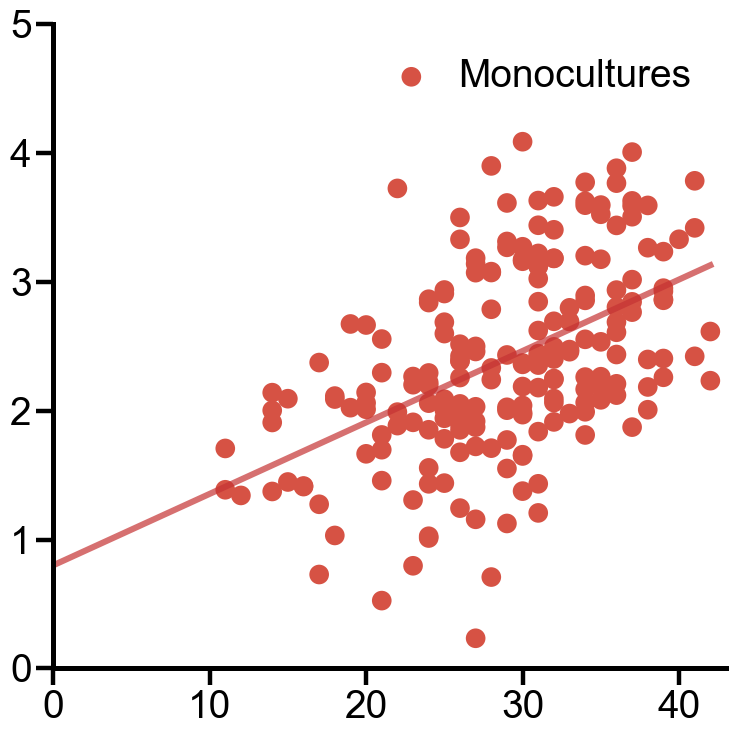

In [3]:
set_panel_style(scale=4)

total_slope = []


plt.figure(figsize=(8, 8))

for i in [0]:
    mask = all_growth_rate[i] > 0.001
    x = all_total_nutrient_count[i][mask]
    y = all_growth_rate[i][mask]


    try:
        plt.scatter(
            x, y,
            color=scatter_color,
            label="Monocultures",
            s=200,       
            edgecolors="none"
        )

        # Fit line
        slope, intercept = np.polyfit(x, y, 1)

        print(pearson_ci(x, y, confidence=0.95))

        xmin = 0
        xmax = int(np.ceil(np.max(x)))
        xx = np.arange(xmin, xmax + 1)
        yy = slope * xx + intercept

        plt.plot(xx, yy, color=set_color, alpha=0.7) 
        total_slope.append(slope)

    except Exception:
        continue

# Axes limits
plt.xlim((0, int(np.ceil(np.max(all_total_nutrient_count[i]))) + 1))
plt.ylim((0, 5))

plt.legend(frameon=False, handletextpad=0.2)

ax = plt.gca()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# plt.xlabel(r"#Nutrients utilized, $M$")
# plt.ylabel(r"Growth rate, $\lambda$ ($h^{-1}$)")
plt.tight_layout()
#plt.savefig('Figure2C_1.pdf', format="pdf", pad_inches=0.5)
plt.show()

{'r': 0.07286281290913149, 'p': 0.302766439181318, 'ci_low': -0.06585056432641209, 'ci_high': 0.20881340454605454, 'n': 202}


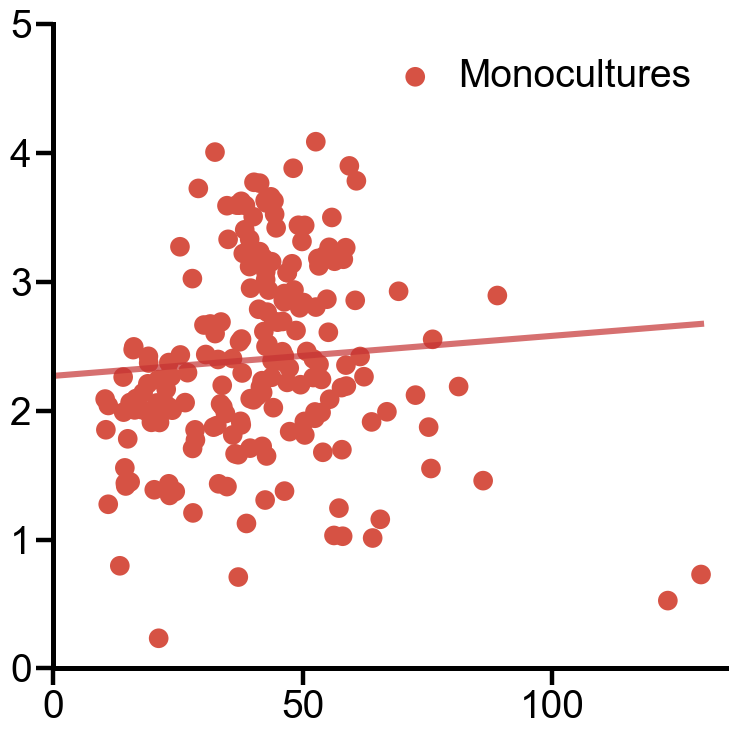

In [4]:
total_slope = []

plt.figure(figsize=(8, 8))

for i in [0]:
    mask = (all_growth_rate[i] > 0.001)
    x = all_total_intake[i][mask]
    y = all_growth_rate[i][mask]

    if len(x) < 2:
        continue

    try:
        plt.scatter(
            x, y,
            color=scatter_color,
            label="Monocultures",
            s=200,          
            edgecolors="none"
        )

        # Fit line
        slope, intercept = np.polyfit(x, y, 1)
        print(pearson_ci(x, y, confidence=0.95))

        xmin = 0
        xmax = float(np.max(x))
        xx = np.linspace(xmin, xmax, 200)
        yy = slope * xx + intercept

        plt.plot(xx, yy, color=set_color, alpha=0.7)
        total_slope.append(slope)

    except Exception:
        continue

plt.xlim((0, float(np.max(all_total_intake[i])) + 5))
plt.ylim((0, 5))

plt.legend(frameon=False, handletextpad=0.1)

ax = plt.gca()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# plt.xlabel(r"Concentration of nutrients utilized" "\n" r"(mmol/gDW/hr), $C$")
# plt.ylabel(r"Growth rate, $\lambda$ ($h^{-1}$)")

plt.tight_layout()

#plt.savefig("Figure2C_2.pdf", format="pdf", pad_inches=0.5)

plt.show()
plt.close()